# 03 - Source components, priors and batching

A source model in GammaBayes is a **prior**: an object whose `eval_log_on_geom(...)` returns the
natural-log expected counts on the geometry.  Most sources are separable,

$$\log \mu(E, l, b) = \underbrace{\log S(E)}_{\text{spectral}} + \underbrace{\log M(l, b)}_{\text{spatial}} + \log X(E, l, b),$$

and are built with `TwoCompFluxPrior(spectral_comp, spatial_comp, binning_geometry, log_exposure_map)`.
This notebook shows the components, how parameters are passed, and the **batching rules** that let
one call evaluate many parameter values at once (slower than literally ***all*** at once, but is less likely to lead to OOM errors).

In [1]:
import os, math, time
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")   # Apple MPS: run the few unsupported ops on the CPU
import numpy as np
import torch
import matplotlib.pyplot as plt
from astropy import units as u

FAST = os.environ.get("GAMMABAYES_DOCS_FAST", "0") == "1"
# device: GAMMABAYES_DOCS_DEVICE=cpu|cuda|mps, else CUDA > Apple MPS > CPU.  MPS has no float64, so it runs in float32.
device = os.environ.get("GAMMABAYES_DOCS_DEVICE") or ("cuda" if torch.cuda.is_available()
                                                      else "mps" if torch.backends.mps.is_available() else "cpu")
torch.set_default_dtype(torch.float32 if device == "mps" else torch.float64)   # float64 where available: exactness over speed
torch.set_default_device(device)                # GammaBayes objects are created on the default device
print(f"torch {torch.__version__} on {device} ({torch.get_default_dtype()}), FAST={FAST}")

from gammabayes import GammaBinning, GammaLogExposure
from gammabayes.response_functions import IRFExtractor
from gammabayes.priors import TwoCompFluxPrior, StaticSourceDistTemplate, DiscreteLogPrior
from gammabayes.priors.spectral_components import PowerLaw, ExpCutoffPowerLaw, BrokenPowerLaw, LogParabola, BroadBrokenPowerLaw
from gammabayes.priors.spatial_components import PointSpatial_PriorComp, GaussianSpatial_PriorComp, IsotropicSpatial_PriorComp
from gammabayes.priors.astro_sources import IsotropicPowerLaw
from gammabayes.core.batching import as_param, batch_size, promote_batch
npy = lambda t: t.detach().cpu().numpy()

geom = GammaBinning(energy_res=10, energy_min=0.1, energy_max=100., lon_res=10, lon_min=-3., lon_max=3., lat_res=10, lat_min=-3., lat_max=3.)
pointing = torch.tensor([0., 0.])
irfs = IRFExtractor(zenith_angle=20, hemisphere="South", prod_vers=5, pointing_dir=pointing, irf_time_seconds=180000)
logexp = GammaLogExposure(binning_geometry=geom, irfs=irfs, pointing_dirs=[pointing], live_times=500 * u.hr)
E = geom.energy_axis

torch 2.15.0 on mps (torch.float32), FAST=False


/Volumes/Extreme SSD/GammaBayes/.gb_venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[wall time: 3.0 s]


## Spectral components

A spectral component is called with the energy axis `(E,)` in TeV and keyword parameters.
Constructor arguments are used as defaults; values passed at call time overrides them during inference.  
The return value is always `(B, E)`: `B = 1` for scalar parameters, `B` for `(B,)` tensors.
Fluxes are in TeV⁻¹ cm⁻² s⁻¹ (per deg² once combined with a spatial map).

scalar call  -> (1, 30)
batched call -> (3, 30)   (one spectrum per index)


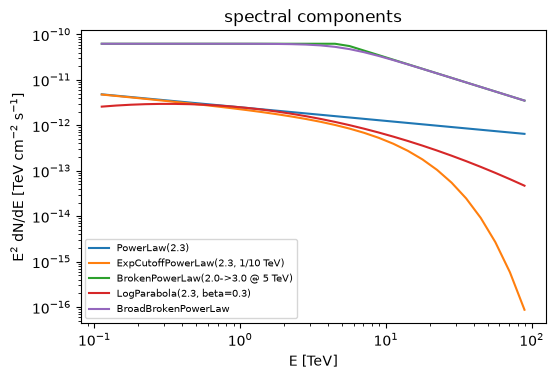

[wall time: 346 ms]


In [2]:
pl = PowerLaw(ref_energy=1., index=2.3, phi0=2.5e-12)            # ~ HESS J1745-290 at 1 TeV
print("scalar call  ->", tuple(pl(E).shape))
idx = torch.tensor([2.0, 2.3, 2.6])
print("batched call ->", tuple(pl(E, index=idx).shape), "  (one spectrum per index)")

comps = {
    "PowerLaw(2.3)": pl(E),
    "ExpCutoffPowerLaw(2.3, 1/10 TeV)": ExpCutoffPowerLaw(index=2.3, lambdaval=0.1, phi0=2.5e-12)(E),
    "BrokenPowerLaw(2.0->3.0 @ 5 TeV)": BrokenPowerLaw(index1=2.0, index2=3.0, break_energy=5., phi0=2.5e-12)(E),
    "LogParabola(2.3, beta=0.3)": LogParabola(index=2.3, beta=0.3, phi0=2.5e-12)(E),
    "BroadBrokenPowerLaw": BroadBrokenPowerLaw(index1=2.0, index2=3.0, cutoff_energy_TeV=5., S=0.3, phi0=2.5e-12)(E),
}
fig, ax = plt.subplots(figsize=(6, 3.8))
for name, ls in comps.items():
    ax.loglog(npy(E), npy(E) ** 2 * np.exp(npy(ls[0])), label=name)
ax.set(xlabel="E [TeV]", ylabel="E$^2$ dN/dE [TeV cm$^{-2}$ s$^{-1}$]", title="spectral components")
ax.legend(fontsize=7)

`LogParabola` uses $\beta\,\log_{10}(E/E_0)$ in the exponent (the power itself is taken with the
natural log), so its `beta` is $1/\ln 10$ of the gammapy / Fermi convention.  `BroadBrokenPowerLaw`
ignores `ref_energy`; the break is at `cutoff_energy_TeV`.


## Spatial components

Spatial components receive the sky grid `(lon, lat, 2)` of pixel centres in degrees and return
`(B, lon, lat)` **log densities per deg²**: for a localised source `exp(map) * dlon * dlat`
sums to the fraction of its flux inside the window, while the isotropic map is 1 deg⁻²
everywhere (its "integral" below is the window area).

point      shape (1, 60, 60)  integral over the window = 1.0000
gaussian   shape (1, 60, 60)  integral over the window = 1.0000
isotropic  shape (1, 60, 60)  integral over the window = 35.9999
point source at (0.03, -0.07): non-zero pixels = 4  integral = 0.9999990463256836


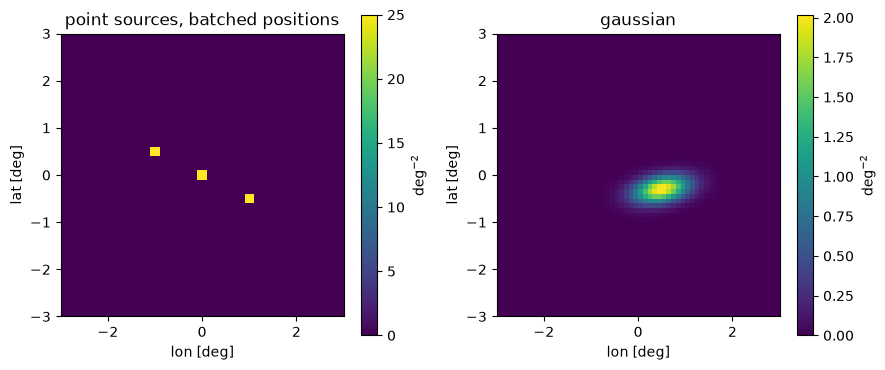

[wall time: 203 ms]


In [3]:
ll = geom.shaped_grid[0, ..., 1:]                 # (lon, lat, 2)
dlon = float(geom.lon_edges[1] - geom.lon_edges[0])
dlat = float(geom.lat_edges[1] - geom.lat_edges[0])

point = PointSpatial_PriorComp(pos_lon=0., pos_lat=0.)
gauss = GaussianSpatial_PriorComp(pos_lon=0.5, pos_lat=-0.3, sigma_lon=0.4, sigma_lat=0.2, rho=0.3)
iso = IsotropicSpatial_PriorComp()

for name, comp in [("point", point), ("gaussian", gauss), ("isotropic", iso)]:
    m = comp(ll)
    print(f"{name:10s} shape {tuple(m.shape)}  integral over the window = {float(torch.exp(m).sum() * dlon * dlat):.4f}")
# a point source between pixel centres is deposited bilinearly on its 4 neighbours (differentiable in position)
off = point(ll, pos_lon=0.03, pos_lat=-0.07)[0]
print("point source at (0.03, -0.07): non-zero pixels =", int((torch.exp(off) > 1e-12).sum()), " integral =", float(torch.exp(off).sum() * dlon * dlat))

fig, ax = plt.subplots(1, 2, figsize=(9, 3.8))
for a, (name, comp, kw) in zip(ax, [("point sources, batched positions", point, dict(pos_lon=torch.tensor([-1., 0., 1.]), pos_lat=torch.tensor([0.5, 0., -0.5]))),
                                   ("gaussian", gauss, {})]):
    m = torch.logsumexp(comp(ll, **kw), dim=0)          # sum the batch for display
    pcm = a.pcolormesh(npy(geom.lon_axis), npy(geom.lat_axis), np.exp(npy(m)).T, shading="auto")
    a.set(title=name, xlabel="lon [deg]", ylabel="lat [deg]", aspect="equal")
    plt.colorbar(pcm, ax=a, label="deg$^{-2}$")
plt.tight_layout()

## How batching works

* a parameter is a Python scalar, a 0-d tensor or a **1-d tensor `(B,)`**;
* several parameters are broadcast to a common `B` (scalars act as `B = 1`; two different
  `B > 1` raise);
* the output has a leading batch axis.

`gammabayes.core.batching` provides the helpers the components use, for writing custom components.

In [4]:
print(as_param(2.0, n_trailing=1).shape, as_param(torch.arange(4.), n_trailing=2).shape)   # (1,1) and (4,1,1)
print("batch_size(scalar, (3,), None) =", batch_size(1.0, torch.zeros(3), None))
try:
    batch_size(torch.zeros(3), torch.zeros(4))
except ValueError as err:
    print("mismatch ->", err)

def log_my_spectrum(energy, index, curvature=0.0):
    """A custom spectral component following the batching rules: (B, E)."""
    Eg = torch.as_tensor(energy).reshape(1, -1)
    index = as_param(index, 1, like=Eg)
    curvature = as_param(curvature, 1, like=Eg)
    x = torch.log(Eg)
    return -index * x - curvature * x ** 2 + math.log(1e-12)

print("custom component:", tuple(log_my_spectrum(E, index=torch.tensor([2., 2.5]), curvature=0.1).shape))

torch.Size([1, 1]) torch.Size([4, 1, 1])
batch_size(scalar, (3,), None) = 3
mismatch -> inconsistent batch sizes 3 and 4


custom component: (2, 30)


[wall time: 6 ms]


## Two-component priors

`TwoCompFluxPrior` broadcasts a `(B1, E)` spectrum against a `(B2, lon, lat)` map,
`B1, B2 ∈ {1, B}`, adds the log exposure and returns `(B, E, lon, lat)`.  With
`squeeze=True` (default) the batch axis is dropped when `B = 1`, so code written for single
parameter values needs no changes.

In [5]:
gc_source = TwoCompFluxPrior(spectral_comp=pl, spatial_comp=point, binning_geometry=geom, log_exposure_map=logexp, name="GC point source")

single = gc_source.eval_log_on_geom(spectral_params={"index": 2.3}, spatial_params={"pos_lon": 0., "pos_lat": 0.})
batch_spec = gc_source.eval_log_on_geom(spectral_params={"index": torch.tensor([2.0, 2.3, 2.6])}, spatial_params={"pos_lon": 0., "pos_lat": 0.})
batch_both = gc_source.eval_log_on_geom(spectral_params={"index": torch.tensor([2.0, 2.3, 2.6])},
                                        spatial_params={"pos_lon": torch.tensor([-0.5, 0., 0.5]), "pos_lat": 0.})
print("single:", tuple(single.shape), " batched spectrum:", tuple(batch_spec.shape), " batched both:", tuple(batch_both.shape))
print("expected counts in 500 h for index 2.0 / 2.3 / 2.6:", npy(torch.exp(batch_spec).sum((1, 2, 3))))
print("squeeze=False keeps the axis:", tuple(gc_source.eval_log_on_geom(spectral_params={"index": 2.3}, spatial_params={"pos_lon": 0., "pos_lat": 0.}, squeeze=False).shape))

single: (30, 60, 60)  batched spectrum: (3, 30, 60, 60)  batched both: (3, 30, 60, 60)
expected counts in 500 h for index 2.0 / 2.3 / 2.6: [167773.03 206581.   290815.75]
squeeze=False keeps the axis: (1, 30, 60, 60)


[wall time: 31 ms]


Parameters that are **not** passed fall back to the constructor defaults, and components are
reusable across priors: the same `PowerLaw` instance can serve several sources.

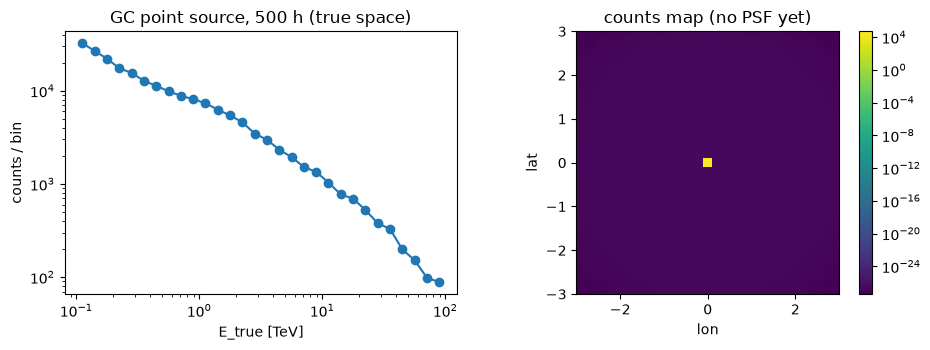

[wall time: 233 ms]


In [6]:
counts_E = torch.exp(single).sum((1, 2))
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.6))
ax[0].loglog(npy(E), npy(counts_E), "o-")
ax[0].set(xlabel="E_true [TeV]", ylabel="counts / bin", title="GC point source, 500 h (true space)")
pcm = ax[1].pcolormesh(npy(geom.lon_axis), npy(geom.lat_axis), npy(torch.exp(single).sum(0)).T, shading="auto", norm="log")
ax[1].set(xlabel="lon", ylabel="lat", aspect="equal", title="counts map (no PSF yet)")
plt.colorbar(pcm, ax=ax[1])
plt.tight_layout()

## Isotropic sources and static templates

* `IsotropicPowerLaw` / `IsotropicBrokenPowerLaw` are ready-made two-component priors with a
  uniform sky map (e.g. the isotropic gamma-ray background, or a stand-in for diffuse emission).
* `StaticSourceDistTemplate` wraps a fixed **flux** tensor (it still gets multiplied by the
  exposure); `StaticDistTemplate` wraps a fixed **rate** tensor.  The CCR background is the
  typical static rate: it comes as a reconstructed-space rate density and is combined with the
  no-acceptance exposure $t\,\Delta V$.

In [7]:
igrb = IsotropicPowerLaw(binning_geometry=geom, index=2.4, phi0=2e-14, log_exposure_map=logexp)   # TeV^-1 cm^-2 s^-1 deg^-2 at 1 TeV (illustrative diffuse level)
print("isotropic source counts:", float(torch.exp(igrb.eval_log_on_geom()).sum()))

g = geom.shaped_grid
logexp_noaeff = GammaLogExposure(binning_geometry=geom, irfs=irfs, pointing_dirs=[pointing], live_times=500 * u.hr, use_log_aeff=False)
log_ccr_rate = irfs.log_bkg_CCR(g[..., 0].flatten(), g[..., 1].flatten(), g[..., 2].flatten(), pointing_dir=pointing).reshape(geom.shape)
ccr = StaticSourceDistTemplate(source_flux_tensor_logtemplate=log_ccr_rate, binning_geometry=geom, log_exposure_map=logexp_noaeff, name="CCR")
log_ccr = ccr.eval_log_on_geom()
print("CCR counts (reco space):", float(torch.exp(log_ccr).sum()), " shape:", tuple(log_ccr.shape))

isotropic source counts: 54299.02734375
CCR counts (reco space): 56547792.0  shape: (30, 60, 60)


[wall time: 31 ms]


## Mixtures and sampling

A model with several sources is the `logaddexp` of their cubes (in log space, with any
amplitude factors added to the logs).  `DiscreteLogPrior.sample(norm, **params)` draws a
Poisson realisation of `norm * exp(cube)`; `sample_categorical(N, **params)` draws exactly `N`
events from the normalised cube.

In [8]:
amp_gc, amp_iso = 1.0, 0.5                                            # relative amplitudes
log_model = torch.logaddexp(torch.logaddexp(single + math.log(amp_gc), igrb.eval_log_on_geom() + math.log(amp_iso)), log_ccr)
print("total expected counts: %.4g  (GC %.3g, iso %.3g, CCR %.3g)" % (torch.exp(log_model).sum(), amp_gc * torch.exp(single).sum(),
                                                                         amp_iso * torch.exp(igrb.eval_log_on_geom()).sum(), torch.exp(log_ccr).sum()))
torch.manual_seed(1)
obs = gc_source.sample(norm=1.0, spectral_params={"index": 2.3}, spatial_params={"pos_lon": 0., "pos_lat": 0.})
print("Poisson realisation of the point source:", tuple(obs.shape), " events:", int(obs.sum()))

total expected counts: 5.678e+07  (GC 2.07e+05, iso 2.71e+04, CCR 5.65e+07)
Poisson realisation of the point source: (30, 60, 60)  events: 206303


[wall time: 15 ms]
